<a href="https://colab.research.google.com/github/layanabinu/Adv_ML_Lab/blob/main/Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ====================================================
# 📦 1. Libraries
# ====================================================
library(readr)
library(dplyr)
library(tm)
library(SnowballC)
library(textstem)
library(caret)
library(e1071)
library(text2vec)
library(data.table)
library(Matrix)
library(keras)
library(tensorflow)
library(reticulate)

set.seed(42)


Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union


Loading required package: NLP

Loading required package: koRpus.lang.en

Loading required package: koRpus

Loading required package: sylly

For information on available language packages for 'koRpus', run

  available.koRpus.lang()

and see ?install.koRpus.lang()



Attaching package: 'koRpus'


The following object is masked from 'package:tm':

    readTagged


The following object is masked from 'package:readr':

    tokenize


Loading required package: ggplot2


Attaching package: 'ggplot2'


The following object is masked from 'package:NLP':

    annotate


Loading required package: lattice


Attaching package: 'e1071'


The following object is masked from 'package:ggplot2':

    element



Attaching package: 'data.table'


The following objects are masked from 'package:dplyr':

    b

In [ ]:

# ====================================================
# 📂 2. Load and Prepare Dataset (Full 1.6M)
# ====================================================
data1 <- read_csv('Dataset/sentiment140.csv', col_names = FALSE)
colnames(data1) <- c("target", "id", "date", "flag", "user", "text")
data1 <- data1 %>% select(target, text)
data1$text <- iconv(data1$text, from = "", to = "UTF-8", sub = "byte")

# Keep only 0 and 4 labels
data1 <- data1 %>% filter(target %in% c(0,4))
data1$sentiment <- factor(data1$target, levels = c(0,4), labels = c("negative","positive"))

Rows: 1600000 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): X3, X4, X5, X6
dbl (2): X1, X2

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


tibble [1,600,000 × 3] (S3: tbl_df/tbl/data.frame)
 $ target   : num [1:1600000] 0 0 0 0 0 0 0 0 0 0 ...
 $ text     : chr [1:1600000] "@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer.  You shoulda got David Carr of Third Day to do it. ;D" "is upset that he can't update his Facebook by texting it... and might cry as a result  School today also. Blah!" "@Kenichan I dived many times for the ball. Managed to save 50%  The rest go out of bounds" "my whole body feels itchy and like its on fire" ...
 $ sentiment: Factor w/ 2 levels "negative","positive": 1 1 1 1 1 1 1 1 1 1 ...


target,text,sentiment
<dbl>,<chr>,<fct>
0,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr of Third Day to do it. ;D",negative
0,is upset that he can't update his Facebook by texting it... and might cry as a result School today also. Blah!,negative
0,@Kenichan I dived many times for the ball. Managed to save 50% The rest go out of bounds,negative
0,my whole body feels itchy and like its on fire,negative
0,"@nationwideclass no, it's not behaving at all. i'm mad. why am i here? because I can't see you all over there.",negative
0,@Kwesidei not the whole crew,negative


     target      text              sentiment     
 Min.   :0   Length:1600000     negative:800000  
 1st Qu.:0   Class :character   positive:800000  
 Median :2   Mode  :character                    
 Mean   :2                                       
 3rd Qu.:4                                       
 Max.   :4                                       


     0      4 
800000 800000 

target      text sentiment 
        0         0         0

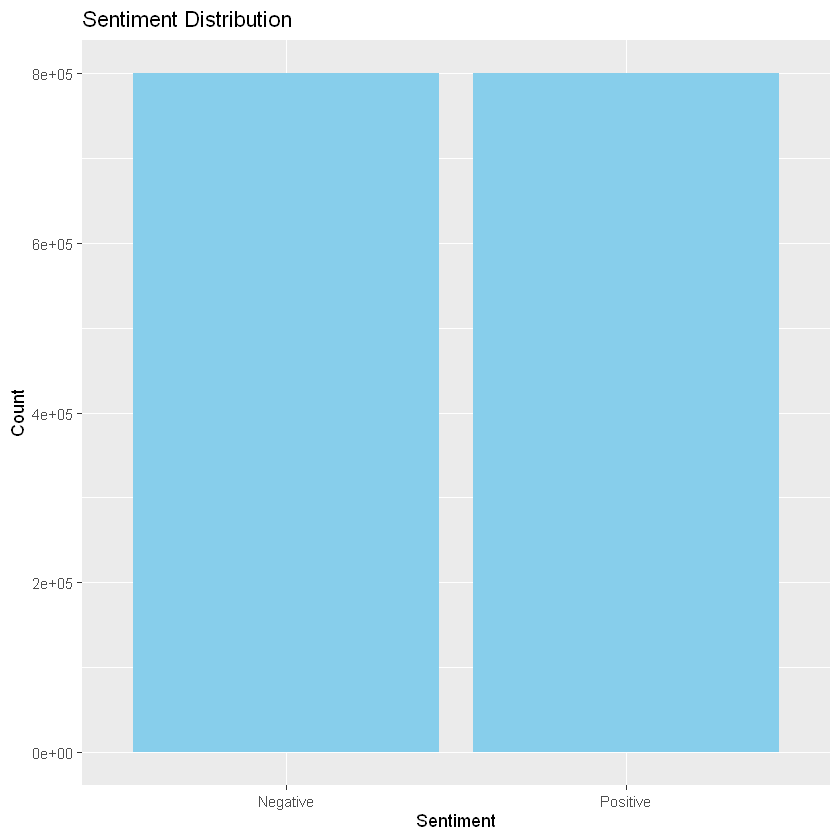

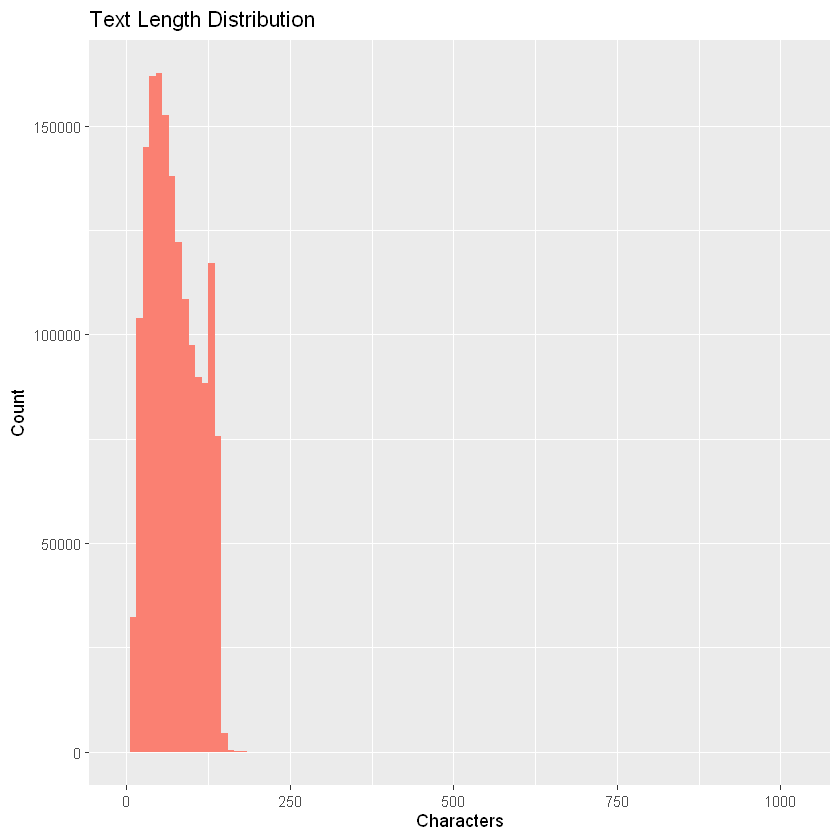

In [ ]:
# EDA before preprocessing

# Structure and first few rows
str(data1)
head(data1)

# Summary statistics
summary(data1)

# Distribution of target variable
table(data1$target)

# Visualize sentiment distribution
library(ggplot2)
ggplot(data1, aes(x = factor(target, levels = c(0, 4), labels = c("Negative", "Positive")))) +
  geom_bar(fill = "skyblue") +
  labs(title = "Sentiment Distribution", x = "Sentiment", y = "Count")

# Check for missing values
colSums(is.na(data1))

# Text length distribution
data1$text_length <- nchar(data1$text)
ggplot(data1, aes(x = text_length)) +
  geom_histogram(binwidth = 10, fill = "salmon") +
  labs(title = "Text Length Distribution", x = "Characters", y = "Count")


In [ ]:
sum(duplicated(data1$text))  # Number of duplicate tweets
data1[duplicated(data1$text),]  # View duplicates


[1] 19112

target,text,sentiment,text_length
<dbl>,<chr>,<fct>,<int>
0,@mandayyy,negative,9
0,and so the editing of 3000 wedding shots begins,negative,47
0,"im lonely keep me company! 22 female, california",negative,49
0,"just been given ma marching orders, gotta go do some work, yay",negative,62
0,"I'm not liking that new iTunes Pricing at all. I mean, I've seen several songs at $1.29, but not only one at $0.69!",negative,115
0,"cant eat, drink or breath properly thanks to the bad throat infection",negative,69
0,has a cold,negative,10
0,This is a bad time to be hooked on Twilight..........11 assignments due by May 29th,negative,83
0,has no followers,negative,16


In [ ]:
if (!require(slam)) install.packages("slam")
library(slam)
library(tm)
corpus <- Corpus(VectorSource(data1$text))
dtm <- DocumentTermMatrix(corpus)
freq_words <- slam::col_sums(dtm)
freq_words <- sort(freq_words, decreasing = TRUE)
head(freq_words, 20)


Loading required package: slam


Attaching package: 'slam'


The following object is masked from 'package:data.table':

    rollup




the    and    you    for   have   that    i'm    but   just   with    was 
518732 295671 237766 214051 143295 128774 127616 124674 124453 113488 102742 
   not   this    get   good    are   like    all    out   your 
102158  88151  80943  77367  75994  75424  74076  68953  64854

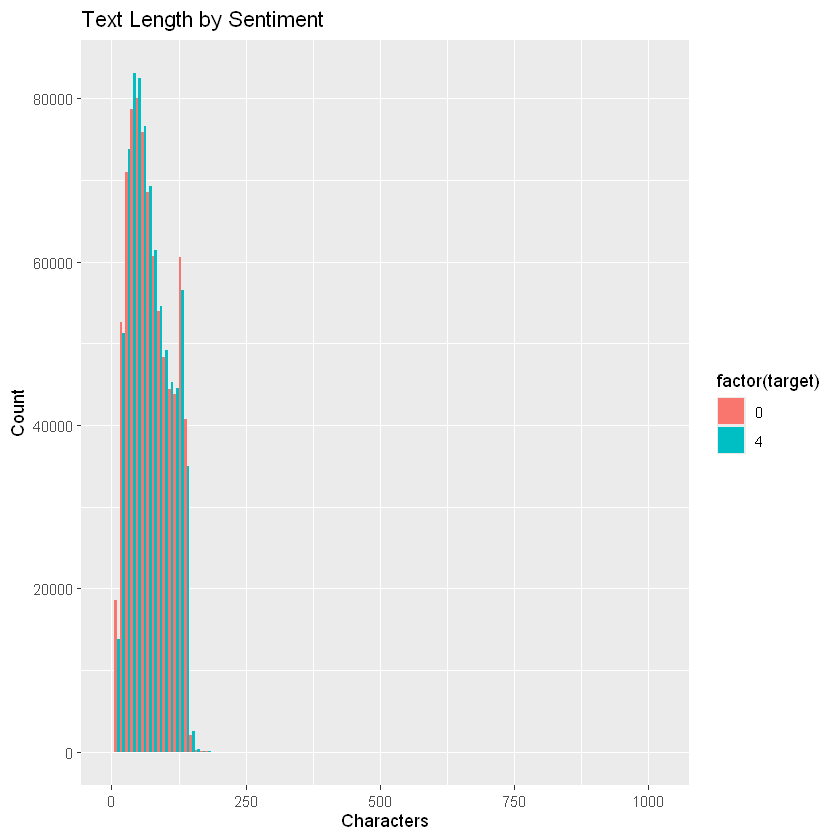

In [ ]:
ggplot(data1, aes(x=text_length, fill=factor(target))) +
  geom_histogram(binwidth=10, position="dodge") +
  labs(title="Text Length by Sentiment", x="Characters", y="Count")


Loading required package: RColorBrewer



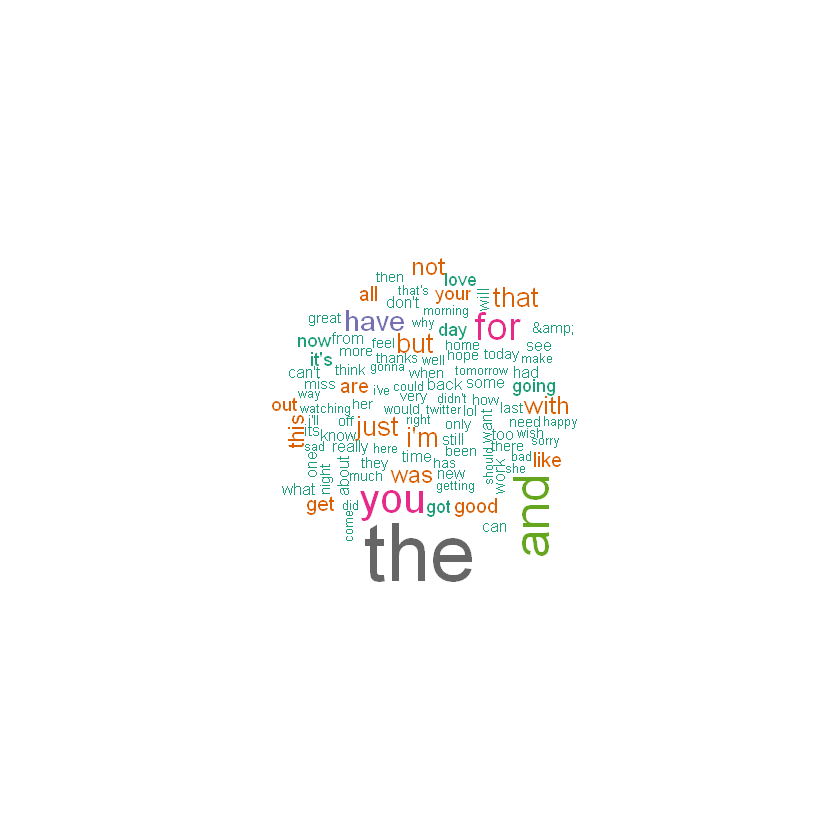

In [ ]:
library(wordcloud)
wordcloud(names(freq_words), freq_words, max.words=100, colors=brewer.pal(8, "Dark2"))


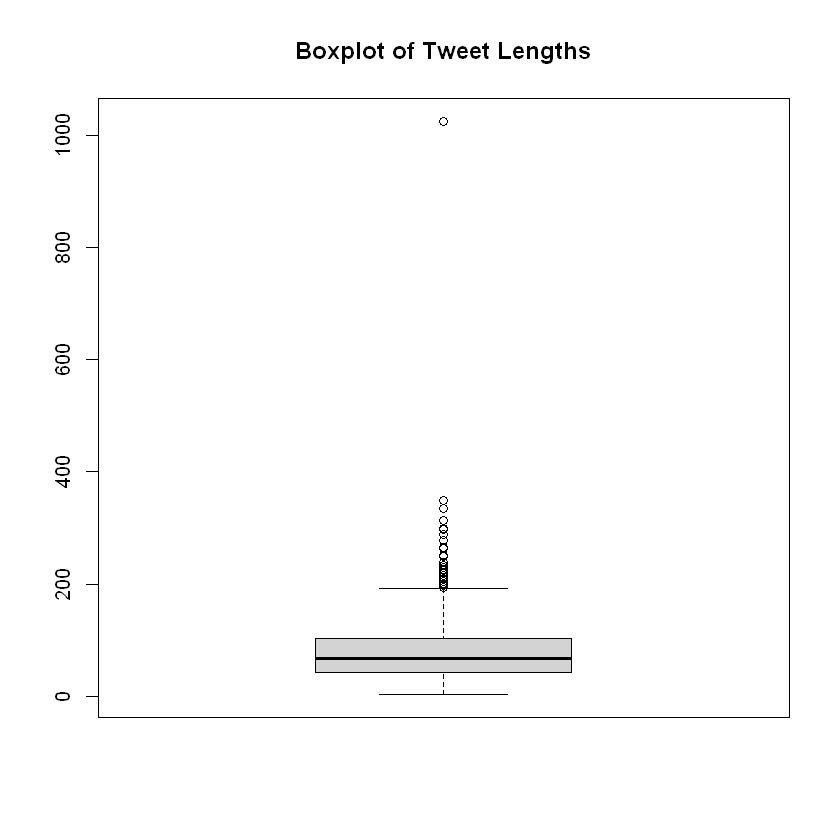

In [ ]:
boxplot(data1$text_length, main="Boxplot of Tweet Lengths")


In [ ]:
sum(grepl("http", data1$text))   # Tweet with URLs
sum(grepl("@", data1$text))      # Tweet with mentions
sum(grepl("#", data1$text))      # Tweet with hashtags


[1] 70183

[1] 746432

[1] 36812

In [ ]:
# ====================================================
# 🧹 3. Text Cleaning
# ====================================================
data1$text <- tolower(data1$text)


In [ ]:
data1$text <- gsub("http\\S+|www\\S+", "", data1$text)


In [ ]:
data1$text <- gsub("@\\w+", "", data1$text)


In [ ]:
data1$text <- gsub("&amp;", "and", data1$text)


In [ ]:
data1$text <- gsub("[^a-z0-9#?!'\\s]", " ", data1$text)


In [ ]:
data1$text <- gsub("\\s+", " ", data1$text)


In [ ]:
data1$text <- trimws(data1$text)


In [ ]:
data1$text <- removeWords(data1$text, stopwords("en"))


In [ ]:
#data1$text <- lemmatize_strings(data1$text)

In [ ]:
# ====================================================
# 🧩 4. Train/Test Split
# ====================================================
set.seed(42)
train_idx <- sample(seq_len(nrow(data1)), size = 0.7 * nrow(data1))
train_data <- data1[train_idx, ]
test_data <- data1[-train_idx, ]

In [ ]:
# ====================================================
# 🔤 5. TF-IDF Feature Extraction  (Memory Safe)
# ====================================================
library(text2vec)
library(Matrix)

# Create iterator
it_train <- itoken(train_data$text, progressbar = FALSE)
vocab <- create_vocabulary(it_train, ngram = c(1L,2L)) %>%
          prune_vocabulary(term_count_min = 5)
vectorizer <- vocab_vectorizer(vocab)

# Sparse Document-Term Matrices
dtm_train <- create_dtm(it_train, vectorizer)

tfidf <- TfIdf$new()
dtm_train_tfidf <- tfidf$fit_transform(dtm_train)

it_test <- itoken(test_data$text, progressbar = FALSE)
dtm_test <- create_dtm(it_test, vectorizer)
dtm_test_tfidf <- tfidf$transform(dtm_test)

# ✅ Keep sparse matrices as-is (no as.matrix!)
# Just store labels separately
y_train <- train_data$sentiment
y_test  <- test_data$sentiment

cat("TF-IDF shapes:\n")
cat("Train:", dim(dtm_train_tfidf)[1], "x", dim(dtm_train_tfidf)[2], "\n")
cat("Test :", dim(dtm_test_tfidf)[1], "x", dim(dtm_test_tfidf)[2], "\n")


TF-IDF shapes:
Train: 1120000 x 196802 
Test : 480000 x 196802 


In [ ]:
# ====================================================
# 🤖 6. Classical ML Models (Final, Memory-Safe)
# ====================================================

library(quanteda)
library(quanteda.textmodels)
library(glmnet)
library(caret)

# --- Labels ---
y_train <- train_data$sentiment
y_test  <- test_data$sentiment
y_train_bin <- ifelse(y_train == "positive", 1, 0)
y_test_bin  <- ifelse(y_test == "positive", 1, 0)

# ====================================================
# 🧩 6.1 Naive Bayes (quanteda.textmodels, Sparse-Safe)
# ====================================================
cat("\n🧠 Training Naive Bayes (quanteda.textmodels)...\n")
dfm_train <- quanteda::as.dfm(dtm_train_tfidf)
dfm_test  <- quanteda::as.dfm(dtm_test_tfidf)
nb_model  <- textmodel_nb(dfm_train, y_train)
pred_nb   <- predict(nb_model, dfm_test)
cat("✅ Naive Bayes done.\n")

# ====================================================
# ⚙️ 6.2 Linear SVM Equivalent (glmnet, Sparse-Safe)
# ====================================================
cat("\n⚙️ Training Linear SVM-equivalent (glmnet)...\n")
# We reuse binary labels (1 = positive, 0 = negative)
cvfit_svm <- cv.glmnet(dtm_train_tfidf, y_train_bin,
                       family = "binomial", alpha = 0, nfolds = 3)
pred_prob_svm <- predict(cvfit_svm, dtm_test_tfidf,
                         s = "lambda.min", type = "response")
pred_svm <- factor(ifelse(pred_prob_svm > 0.5, "positive", "negative"),
                   levels = c("negative", "positive"))
cat("✅ Linear SVM-equivalent done.\n")



# ====================================================
# 🧾 6.4 Evaluation
# ====================================================
cat("\n================ MODEL PERFORMANCE ================\n")

cat("\n📊 Naive Bayes Results:\n")
print(confusionMatrix(pred_nb, y_test))

cat("\n📊 SVM (glmnet) Results:\n")
print(confusionMatrix(pred_svm, y_test))



# Accuracy summary
acc_nb  <- mean(pred_nb == y_test)
acc_svm <- mean(pred_svm == y_test)


cat("\n✅ Accuracy Summary:\n")
cat("Naive Bayes:", round(acc_nb * 100, 2), "%\n")
cat("SVM (glmnet):", round(acc_svm * 100, 2), "%\n")



Package version: 4.3.1
Unicode version: 15.1
ICU version: 74.1

Parallel computing: 4 of 4 threads used.

See https://quanteda.io for tutorials and examples.


Attaching package: 'quanteda'


The following objects are masked from 'package:koRpus':

    tokens, types


The following object is masked from 'package:tm':

    stopwords


The following objects are masked from 'package:NLP':

    meta, meta<-


Loaded glmnet 4.1-10




🧠 Training Naive Bayes (quanteda.textmodels)...
✅ Naive Bayes done.

⚙️ Training Linear SVM-equivalent (glmnet)...
✅ Linear SVM-equivalent done.

================ MODEL PERFORMANCE ================

📊 Naive Bayes Results:
Confusion Matrix and Statistics

          Reference
Prediction negative positive
  negative   188687    58352
  positive    51108   181853
                                          
               Accuracy : 0.772           
                 95% CI : (0.7708, 0.7731)
    No Information Rate : 0.5004          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.5439          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.7869          
            Specificity : 0.7571          
         Pos Pred Value : 0.7638          
         Neg Pred Value : 0.7806          
             Prevalence : 0.4996   

In [ ]:
# Install R kernel + system dependencies
%apt-get install -y r-base

# Install Python TensorFlow 2.15 (compatible with R keras)
%pip install tensorflow==2.15 keras==2.15
%pip install numpy==1.26



ERROR: Error in parse(text = input): <text>:2:1: unexpected input
1: # Install R kernel + system dependencies
2: %apt-get install -y r-base
   ^


In [ ]:
# ====================================================
# ⚙️ 7. Tokenization for Deep Models (Keras)
# ====================================================
max_words <- 50000
max_len <- 40
tokenizer <- text_tokenizer(num_words = max_words, oov_token = "<OOV>")
tokenizer %>% fit_text_tokenizer(data1$text)

train_seq <- texts_to_sequences(tokenizer, train_data$text)
test_seq  <- texts_to_sequences(tokenizer, test_data$text)
x_train <- pad_sequences(train_seq, maxlen = max_len)
x_test  <- pad_sequences(test_seq, maxlen = max_len)
y_train <- as.numeric(train_data$sentiment) - 1
y_test  <- as.numeric(test_data$sentiment) - 1

embedding_dim <- 100

In [ ]:
# ====================================================
# 🧠 8. Define RNN / GRU / LSTM Models
# ====================================================
build_model <- function(type) {
  model <- keras_model_sequential() %>%
    layer_embedding(input_dim = max_words, output_dim = embedding_dim, input_length = max_len) %>%
    layer_dropout(0.2)
  if (type == "RNN") {
    model <- model %>% layer_simple_rnn(units = 128)
  } else if (type == "GRU") {
    model <- model %>% layer_gru(units = 128)
  } else {
    model <- model %>% layer_lstm(units = 128)
  }
  model %>%
    layer_dense(64, activation = "relu") %>%
    layer_dropout(0.3) %>%
    layer_dense(1, activation = "sigmoid") %>%
    compile(optimizer = "adam", loss = "binary_crossentropy", metrics = "accuracy")
  return(model)
}

model_rnn <- build_model("RNN")
model_gru <- build_model("GRU")
model_lstm <- build_model("LSTM")


In [ ]:
# ====================================================
# 🔁 9. Train Neural Models
# ====================================================
epochs <- 3
batch_size <- 1024

cat("\nTraining Simple RNN...\n")
history_rnn <- model_rnn %>% fit(x_train, y_train,
                                 batch_size = batch_size, epochs = epochs,
                                 validation_split = 0.1, verbose = 2)

cat("\nTraining GRU...\n")
history_gru <- model_gru %>% fit(x_train, y_train,
                                 batch_size = batch_size, epochs = epochs,
                                 validation_split = 0.1, verbose = 2)

cat("\nTraining LSTM...\n")
history_lstm <- model_lstm %>% fit(x_train, y_train,
                                   batch_size = batch_size, epochs = epochs,
                                   validation_split = 0.1, verbose = 2)


Training Simple RNN...

Training GRU...

Training LSTM...


In [ ]:
# ====================================================
# 📊 10. Evaluate RNN / GRU / LSTM
# ====================================================
evaluate_model <- function(model, name) {
  preds <- model %>% predict(x_test)
  preds_bin <- ifelse(preds > 0.5, "positive", "negative")
  preds_bin <- factor(preds_bin, levels = c("negative","positive"))
  cat("\n📈", name, "Results:\n")
  print(confusionMatrix(preds_bin, test_data$sentiment))
}
evaluate_model(model_rnn, "RNN")
evaluate_model(model_gru, "GRU")
evaluate_model(model_lstm, "LSTM")


📈 RNN Results:
Confusion Matrix and Statistics

          Reference
Prediction negative positive
  negative   185517    51363
  positive    54278   188842
                                          
               Accuracy : 0.7799          
                 95% CI : (0.7787, 0.7811)
    No Information Rate : 0.5004          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.5598          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.7736          
            Specificity : 0.7862          
         Pos Pred Value : 0.7832          
         Neg Pred Value : 0.7767          
             Prevalence : 0.4996          
         Detection Rate : 0.3865          
   Detection Prevalence : 0.4935          
      Balanced Accuracy : 0.7799          
                                          
       'Positive' Class : n